# Monte Carlo Simulation to estimate aliasing between 2 probablity densities

## The idea

We have two probability densities $f_1$ and $f_2$ (two "bell curves"). We want to know **how much they overlap**, i.e. the area of the region that lies under both curves at the same time:

$$\text{OVL} = \int \min\big(f_1(x), f_2(x)\big)\,dx$$

Each density has a total area of 1, so the overlap is between **0** (the curves do not touch) and **1** (the curves are identical). For example, an overlap of 0.27 means that 27 % of the probability mass is shared by the two distributions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The Gaussian density

The Gaussian (normal) density with mean $\mu$ and standard deviation $\sigma$ is

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

- $\mu$ is the centre of the bell,
- $\sigma$ is its width: a larger $\sigma$ gives a wider and flatter bell,
- the factor $\frac{1}{\sigma\sqrt{2\pi}}$ makes the total area equal to 1.

Below, the red area is the overlap we want to compute.

In [2]:
def gaussian(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu)**2 / sigma**2))

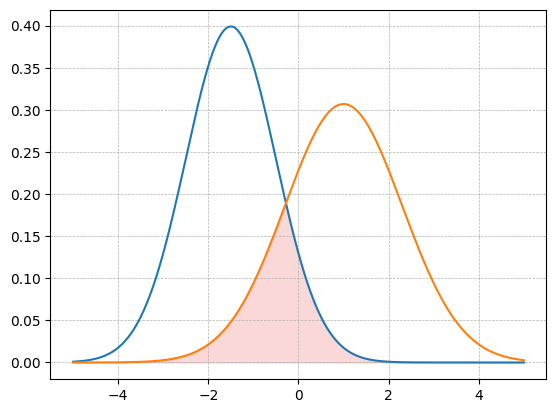

In [3]:
x = np.linspace(-5, 5, 1000)
MU = [-1.5, 1.0]
SIGMA = [1.0, 1.3]
gauss_1 = gaussian(x, mu=-1.5, sigma=1)
gauss_2 = gaussian(x, mu=+1.0, sigma=1.3)

plt.plot(x, gauss_1, label=f'σ={SIGMA[0]} - μ={MU[0]}')
plt.plot(x, gauss_2, label=f'σ={SIGMA[1]} - μ={MU[1]}')
plt.fill_between(x, np.minimum(gauss_1, gauss_2), color='lightcoral', alpha=0.3)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

### Analytic overlap of two Gaussians

The overlap coefficient is the area under the lower of the two curves:
$$\text{OVL} = \int_{-\infty}^{+\infty} \min\big(f_1(x), f_2(x)\big)\,dx$$

**Crossing points.** Setting $f_1(x) = f_2(x)$ and taking the log gives a quadratic $Ax^2 + Bx + C = 0$ with
$$A = \frac{1}{\sigma_1^2} - \frac{1}{\sigma_2^2}, \quad B = -2\left(\frac{\mu_1}{\sigma_1^2} - \frac{\mu_2}{\sigma_2^2}\right), \quad C = \frac{\mu_1^2}{\sigma_1^2} - \frac{\mu_2^2}{\sigma_2^2} + 2\ln\frac{\sigma_1}{\sigma_2}$$
When $\sigma_1 \neq \sigma_2$ there are always two real roots $a < b$.

**Piecewise integration.** Between the roots the narrow density is the higher one, so the minimum is the wide density. Outside the roots it is the other way around, because the wide density has heavier tails. With $\Phi_n$ and $\Phi_w$ the CDFs of the narrow and wide Gaussians:
$$\text{OVL} = \Phi_n(a) + \big[\Phi_w(b) - \Phi_w(a)\big] + \big[1 - \Phi_n(b)\big]$$

*Note:* the case $\sigma_1 = \sigma_2$ ($A = 0$, a single crossing at $\frac{\mu_1 + \mu_2}{2}$) is not handled.

In [4]:
from scipy.stats import norm

def analytic(m1, s1, m2, s2):
    A = 1/s1**2 - 1/s2**2
    B = -2 * (m1/s1**2 - m2/s2**2)
    C = m1**2/s1**2 - m2**2/s2**2 + 2*np.log(s1/s2)
    a, b = np.sort(np.roots([A, B, C]))
    narrow, wide = ((m1, s1), (m2, s2)) if s1 < s2 else ((m2, s2), (m1, s1))
    return (norm.cdf(a, *narrow)
            + norm.cdf(b, *wide) - norm.cdf(a, *wide)
            + norm.sf(b, *narrow))

exact = analytic(MU[0], SIGMA[0], MU[1], SIGMA[1])
print(f"Analytic overlap area between the two Gaussians: {exact}")


Analytic overlap area between the two Gaussians: 0.2736385505227519


## Monte Carlo integration

Idea: **an area is a width times an average height.** If we pick $n$ points $x_i$ uniformly at random in $[a, b]$, the average of $f(x_i)$ is close to the average height of the curve, so

$$\int_a^b f(x)\,dx \approx (b - a) \cdot \frac{1}{n}\sum_{i=1}^{n} f(x_i)$$

Here $f = \min(f_1, f_2)$ and $[a, b] = [-5, 5]$, which contains almost all of the mass of both curves.

Since the estimate is an average of $n$ random values, its typical error (the **standard error**) is

$$\text{std error} = \frac{\text{std of the values } (b-a) f(x_i)}{\sqrt{n}}$$

We can compute it from the samples themselves, without knowing the true answer.

In [5]:
def monte_carlo(func, x_min, x_max, num_samples):
    samples = np.random.uniform(x_min, x_max, num_samples)
    values = (x_max - x_min) * func(samples)
    integral_estimate =  values.mean()
    std_err = values.std(ddof=1) / np.sqrt(num_samples)
    return integral_estimate, std_err

In [6]:
f = lambda x: np.minimum(gaussian(x, mu=-1.5, sigma=1), gaussian(x, mu=1.0, sigma=1.3))

pred, err = monte_carlo(f, -5, 5, 100000)
print(f"Monte Carlo estimate of the overlap area: {pred}")
print(f"Standard error of the estimate: {err}")

Monte Carlo estimate of the overlap area: 0.2729159688980138
Standard error of the estimate: 0.0014843359599985677


## Does the error really decrease like $1/\sqrt{n}$?

We now know the exact answer, so we can measure the real error $|\text{estimate} - \text{exact}|$ for different numbers of points $n$. On a log-log plot, a $1/\sqrt{n}$ decrease is a straight line of slope $-1/2$. With a single run per $n$ the points are noisy, but they should follow the dashed line.

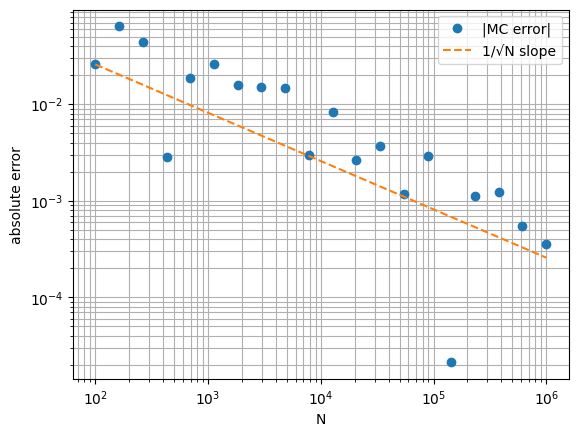

In [7]:
Ns = np.logspace(2, 6, 20).astype(int)
errs = [abs(monte_carlo(f, -5, 5, n)[0] - exact) for n in Ns]

plt.loglog(Ns, errs, 'o', label='|MC error|')
plt.loglog(Ns, errs[0] * np.sqrt(Ns[0] / Ns), '--', label='1/√N slope')
plt.xlabel('N'); plt.ylabel('absolute error'); plt.legend(); plt.grid(True, which='both')


# Benchmark Time

## How precise is the estimate?

To see the error properly, we run 100 independent simulations of $10^7$ points each and record the estimate along the way.

The theory says that a single run has a typical error

$$\text{std} = \frac{\sigma_f}{\sqrt{n}}, \qquad \sigma_f^2 = (b-a)\int_a^b f(x)^2\,dx - \left(\int_a^b f(x)\,dx\right)^2$$

where $\sigma_f$ is the spread of the values $(b-a) f(x_i)$. It is a fixed number (about 0.47 here), so once again the error decreases like $1/\sqrt{n}$.

In [8]:
import numba

@numba.njit(fastmath=True)
def overlap_integrand(x, m1, s1, m2, s2):
    g1 = np.exp(-0.5 * ((x - m1) / s1)**2) / (s1 * np.sqrt(2 * np.pi))
    g2 = np.exp(-0.5 * ((x - m2) / s2)**2) / (s2 * np.sqrt(2 * np.pi))
    return min(g1, g2)

@numba.njit(parallel=True, fastmath=True)
def many_runs(n_runs, n, step, x_min, x_max, m1, s1, m2, s2):
    # Each row is an independent run: running estimate of the overlap every `step` samples
    k = n // step
    width = x_max - x_min
    out = np.empty((n_runs, k))
    for r in numba.prange(n_runs):                                 # runs are independent -> one per thread
        acc = 0.0
        for i in range(k):
            for _ in range(step):
                x = x_min + width * np.random.random()             # uniform sample in [x_min, x_max]
                acc += overlap_integrand(x, m1, s1, m2, s2)
            out[r, i] = width * acc / ((i + 1) * step)
    return out

In [9]:
NUM_SAMPLES = 10_000_000
STEP        = 100
N_RUNS      = 100
X_MIN, X_MAX = -5, 5

runs = many_runs(N_RUNS, NUM_SAMPLES, STEP, X_MIN, X_MAX,
                 MU[0], SIGMA[0], MU[1], SIGMA[1])                 # shape (N_RUNS, NUM_SAMPLES // STEP)

n_values = STEP * np.arange(1, runs.shape[1] + 1)
print(n_values.shape)

/home/ropouillard/.virtualenvs/MonteCarlo/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


(100000,)


In [10]:
from scipy.integrate import quad

ovl_mean = runs.mean(axis=0)
ovl_std  = runs.std(axis=0, ddof=1)

# Theoretical std of one run: (b - a) * std(f(U)) / sqrt(n), with U ~ Uniform(a, b)
# Var[(b - a) f(U)] = (b - a) * ∫ f² dx - (∫ f dx)²
f_scalar = lambda x: min(gaussian(x, MU[0], SIGMA[0]), gaussian(x, MU[1], SIGMA[1]))
I1 = quad(f_scalar, X_MIN, X_MAX, limit=200)[0]
I2 = quad(lambda x: f_scalar(x)**2, X_MIN, X_MAX, limit=200)[0]
sigma_f = np.sqrt((X_MAX - X_MIN) * I2 - I1**2)

## Reading the plots

- **Left:** the estimate as a function of the number of points $n$. The grey curves are individual runs: they wobble a lot at first, then settle around the exact value (dashed line). The blue band (mean ± 1 std) shows how far a single run typically is from the truth; it gets narrower as $n$ grows.
- **Right:** the measured spread of the runs compared with the formula $\sigma_f/\sqrt{n}$. Both are straight lines of slope $-1/2$ on a log-log plot, and they should overlap.

Averaging the 100 runs divides the error by $\sqrt{100} = 10$.

n = 1e+07 : OVL = 0.273618 ± 1.4e-04 (std of one run)
Error on the mean of 100 runs : ± 1.4e-05
Analytic overlap : 0.273639 (difference : -2.0e-05)


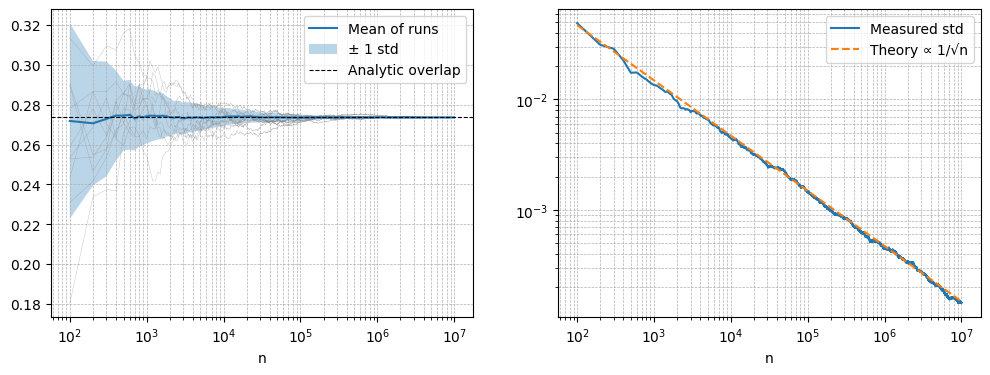

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Convergence: mean ± 1 std, with a few individual runs in the background
ax1.plot(n_values, runs[:10].T, color='gray', lw=0.3, alpha=0.5)
ax1.plot(n_values, ovl_mean, color='C0', label='Mean of runs')
ax1.fill_between(n_values, ovl_mean - ovl_std, ovl_mean + ovl_std, alpha=0.3, label='± 1 std')
ax1.axhline(exact, color='black', ls='--', lw=0.8, label='Analytic overlap')
ax1.set_xscale('log'); ax1.set_xlabel('n'); ax1.legend()
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Measured std vs theory: sigma_f / sqrt(n)
ax2.loglog(n_values, ovl_std, label='Measured std')
ax2.loglog(n_values, sigma_f / np.sqrt(n_values), '--', label='Theory ∝ 1/√n')
ax2.set_xlabel('n'); ax2.legend()
ax2.grid(True, which='both', linestyle='--', linewidth=0.5)


print(f'n = {n_values[-1]:.0e} : OVL = {ovl_mean[-1]:.6f} ± {ovl_std[-1]:.1e} (std of one run)')
print(f'Error on the mean of {N_RUNS} runs : ± {ovl_std[-1] / np.sqrt(N_RUNS):.1e}')
print(f'Analytic overlap : {exact:.6f} (difference : {ovl_mean[-1] - exact:+.1e})')